# Quasiparticle interference around one impurity

An impurity on a surface scatters the electrons. The scattered waves interfere
with the incoming ones, so the local density of states gets standing waves
around the impurity. A scanning-tunnelling microscope images these waves, and
the Fourier transform of the image shows the scattering vectors
$\mathbf q = \mathbf k - \mathbf k'$ that join two states at the same energy.
This is quasiparticle interference (QPI).

Here we take a square sheet of hydrogen atoms with one impurity on an atom, at
the Fermi level. Its Fermi surface is a rounded square around $\Gamma$, so we
expect the strongest $\mathbf q$ at $2k_F$, the vectors across the Fermi surface.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from defuqumat import Calculator

sheet = Calculator.from_file('../docs/figures/stm_qpi/h-sheet.in',
                             pseudo_dir='../tests/data/pseudo')
fermi = sheet.get_scf().fermi_energy
qpi = sheet.get_qpi(0.5, 0.7, impurity=0, energies=[fermi],
                    readers=('ldos', 'landauer'), exit_height=0.3,
                    shape=(4, 4), broadening=0.03, grid=(32, 32, 1))
print(f'T-matrix {qpi.t_matrix[0, 0]:.4f} Ry, left at the supercell edge {qpi.wraparound[0, 0]:.4f}')

T-matrix 0.0431-0.0994j Ry, left at the supercell edge 0.0024


## What is computed

The impurity is a small Gaussian $\phi$ on the atom, with the potential
$V|\phi\rangle\langle\phi|$ and $V = 0.5$ Ry. For this potential the multiple
scattering sums to one number at each energy, the T-matrix:

$$T(\omega) = \frac{V}{1 - V g_0(\omega)},\qquad
g_0(\omega) = \frac1N\sum_{n\mathbf k}\frac{|\langle\psi_{n\mathbf k}|\phi\rangle|^2}{\omega-\varepsilon_{n\mathbf k}+i\eta},
\qquad G = G_0 + G_0\,T\,G_0 .$$

The $32\times32$ k-mesh is a supercell of 1024 cells with the impurity in the
middle. The printed number says that the waves have decayed at its edge, so the
map does not see the next impurity.

We read $G$ at the tip, 3 bohr above the sheet, in two ways. The first is the
local density of states at the tip, the Tersoff-Hamann answer. The second is the
transmission from the tip point to an exit plane 3 bohr below the sheet,
$\int_{\rm exit}|G(\mathbf r,\mathbf r')|^2 d^2r'$. This weights each scattered
wave by how well it tunnels through the sheet, which is the matrix element of
the STM.

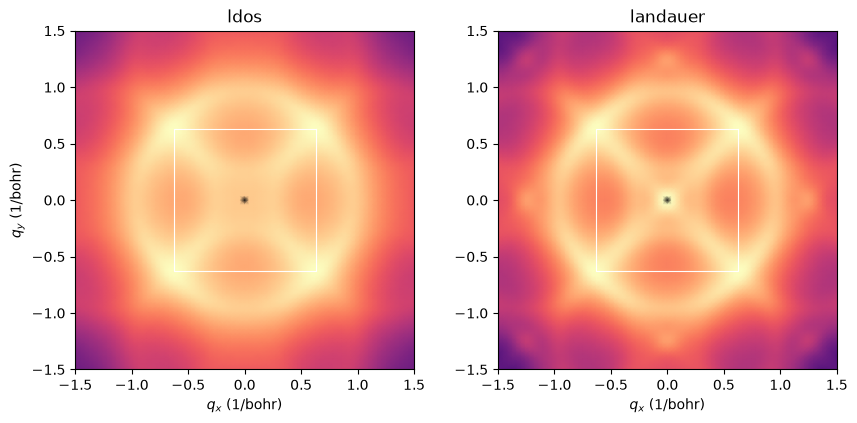

In [2]:
bg = np.asarray(sheet.system.cell.bg)[:2, :2]
n, m = qpi.divisions, qpi.shape
p = [np.fft.fftshift(np.fft.fftfreq(n[i] * m[i], d=1 / (n[i] * m[i]))) / n[i] for i in (0, 1)]
f1, f2 = np.meshgrid(*p, indexing='ij')
q = f1[..., None] * bg[0] + f2[..., None] * bg[1]
zone = 0.5 * np.array([[1, 1], [-1, 1], [-1, -1], [1, -1], [1, 1]]) @ bg

fig, axes = plt.subplots(1, 2, figsize=(10, 4.4))
for ax, reader in zip(axes, ['ldos', 'landauer']):
    image = qpi.qpi[reader][0].copy()
    image[tuple(s // 2 for s in image.shape)] = 0.0      # the mean, q = 0
    ax.pcolormesh(q[..., 0], q[..., 1], np.log10(image / image.max() + 1e-6),
                  shading='gouraud', cmap='magma', vmin=-3, vmax=0)
    ax.plot(zone[:, 0], zone[:, 1], 'w-', lw=0.8)
    ax.set(xlim=(-1.5, 1.5), ylim=(-1.5, 1.5), aspect='equal', xlabel='$q_x$ (1/bohr)', title=reader)
axes[0].set_ylabel('$q_y$ (1/bohr)')
plt.show()

Both patterns show the $2k_F$ contour, a rounded square at about 0.9 bohr$^{-1}$
from $q = 0$, which is twice the Fermi wavevector. Its copies shifted by the
reciprocal lattice vectors cross it, because the tip samples the sheet at the
atomic scale. The two readers show the same contour, so the scattering vectors
are set by the band structure. What changes is the weight along the contour.

In [3]:
size = np.linalg.norm(q, axis=-1)
angle = np.degrees(np.arctan2(q[..., 1], q[..., 0])) % 90
ring = (size > 0.3) & (size < 1.0)
for reader in ('ldos', 'landauer'):
    image = qpi.qpi[reader][0]
    axial = image[ring & ((angle < 5) | (angle > 85))].max()
    diagonal = image[ring & (np.abs(angle - 45) < 5)].max()
    print(f'{reader:9s} axial / diagonal 2k_F peak {axial / diagonal:.3f}')

ldos      axial / diagonal 2k_F peak 0.495
landauer  axial / diagonal 2k_F peak 0.424


The peaks along the axes join the flat sides of the Fermi surface, near the X
points. These states have a large $|\mathbf k_\parallel|$, so they decay faster
into the vacuum, as
$e^{-\sqrt{\kappa_0^2 + k_\parallel^2}\,z}$, and they tunnel less to the exit plane.
So with the matrix element of the STM the axial peaks are about 14% weaker,
compared with the diagonal ones, than the local density of states says. On a
$40\times40$ mesh with $\eta = 0.025$ Ry the same factor is 11%, so the size of the
effect moves by a few per cent with the mesh, and its sign does not.

The algebra is checked in `tests/unit/test_qpi_machinery.py` against a dense
inverse of the Hamiltonian of the whole supercell, and against a real-space
integral over the exit plane. The checks on converged surfaces are in
`tests/regression/test_qpi.py`.